In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

Load Iris dataset

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

df.rename(columns={
    "sepal length (cm)": "sepal_length",
    "sepal width (cm)": "sepal_width",
    "petal length (cm)": "petal_length",
    "petal width (cm)": "petal_width"
}, inplace=True)

print(df.head())
print(df.describe())

sns.set_theme(style="whitegrid")

   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  setosa
1           4.9          3.0           1.4          0.2       0  setosa
2           4.7          3.2           1.3          0.2       0  setosa
3           4.6          3.1           1.5          0.2       0  setosa
4           5.0          3.6           1.4          0.2       0  setosa
       sepal_length  sepal_width  petal_length  petal_width      target
count    150.000000   150.000000    150.000000   150.000000  150.000000
mean       5.843333     3.057333      3.758000     1.199333    1.000000
std        0.828066     0.435866      1.765298     0.762238    0.819232
min        4.300000     2.000000      1.000000     0.100000    0.000000
25%        5.100000     2.800000      1.600000     0.300000    0.000000
50%        5.800000     3.000000      4.350000     1.300000    1.000000
75%        6.400000     3.300000      5.100000     1.800000    2

Histogram

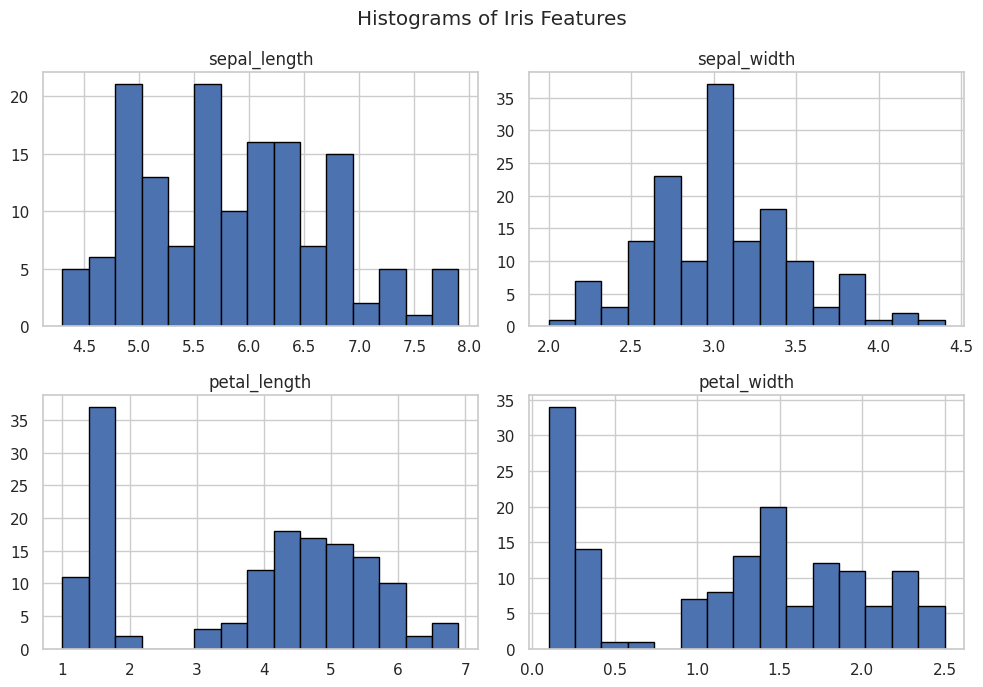

In [3]:
df[["sepal_length", "sepal_width",
    "petal_length", "petal_width"]].hist(
    figsize=(10, 7), bins=15, edgecolor="black"
)
plt.suptitle("Histograms of Iris Features")
plt.tight_layout()
plt.show()

Scatter plot

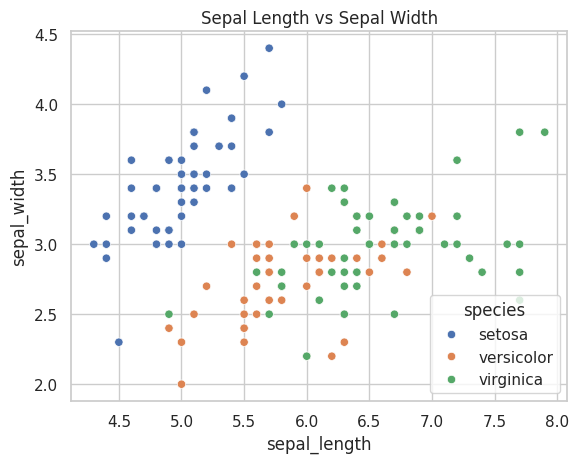

In [4]:
sns.scatterplot(
    data=df,
    x="sepal_length",
    y="sepal_width",
    hue="species"
)
plt.title("Sepal Length vs Sepal Width")
plt.show()

Pair plot

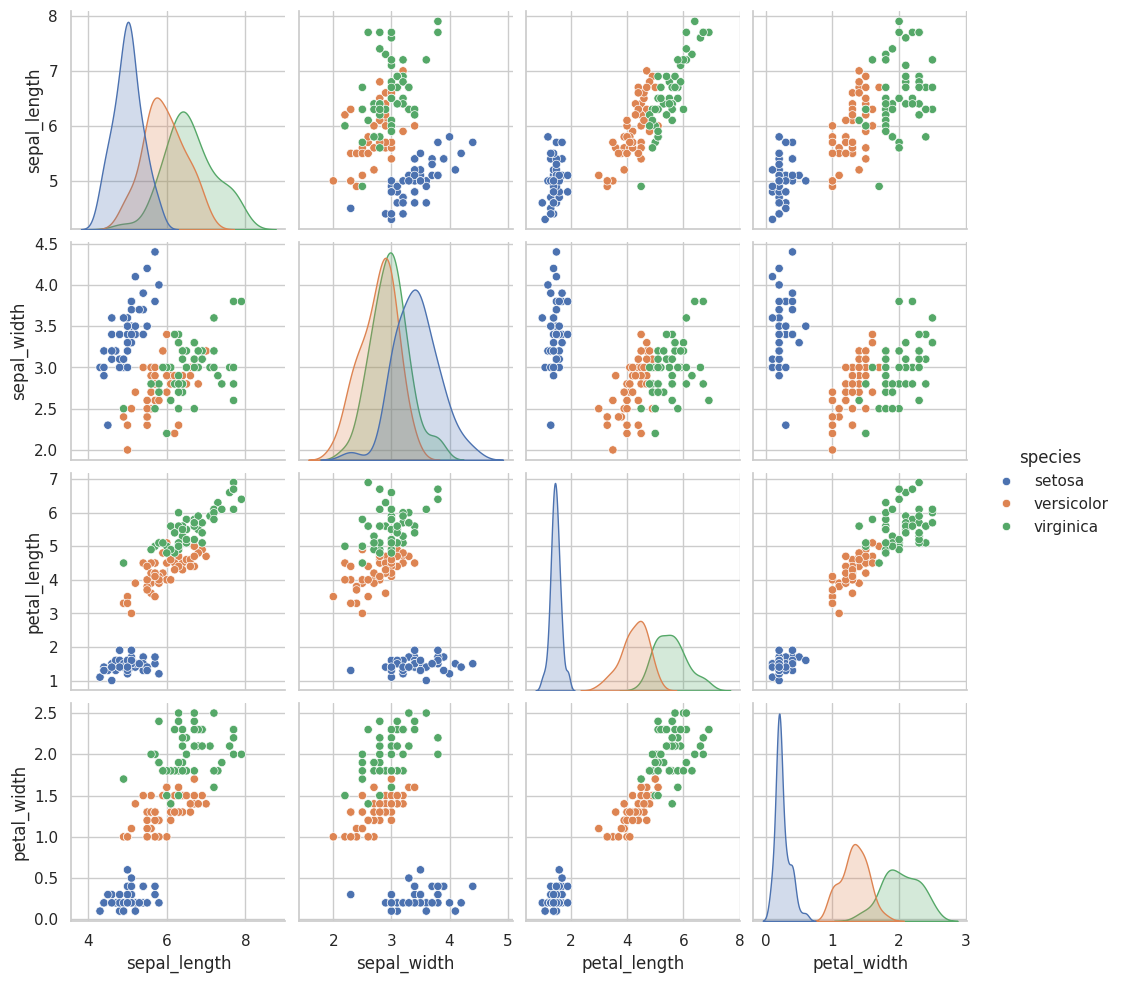

In [5]:
sns.pairplot(
    df,
    vars=["sepal_length", "sepal_width",
          "petal_length", "petal_width"],
    hue="species"
)
plt.show()

Box plot

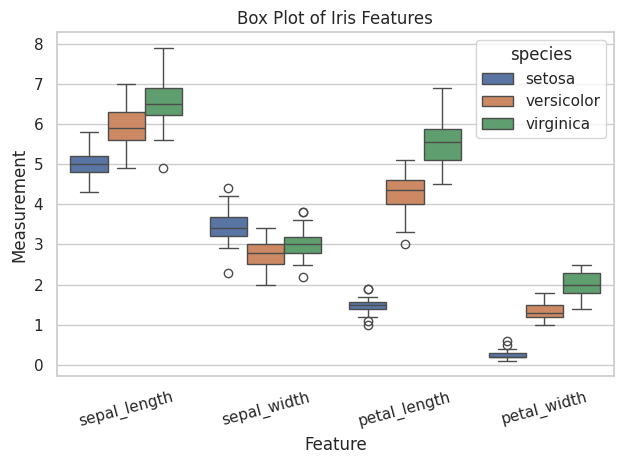

In [6]:
df_long = df.melt(
    id_vars="species",
    value_vars=["sepal_length", "sepal_width",
                "petal_length", "petal_width"],
    var_name="Feature",
    value_name="Measurement"
)

sns.boxplot(
    data=df_long,
    x="Feature",
    y="Measurement",
    hue="species"
)
plt.title("Box Plot of Iris Features")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Violin plot

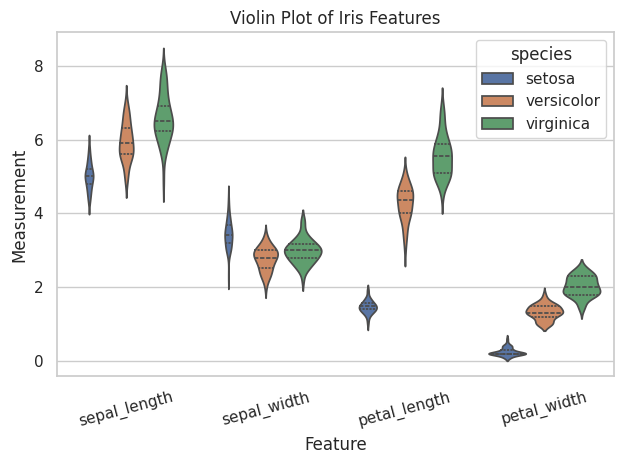

In [7]:
sns.violinplot(
    data=df_long,
    x="Feature",
    y="Measurement",
    hue="species",
    inner="quartile"
)
plt.title("Violin Plot of Iris Features")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Correlation heatmap

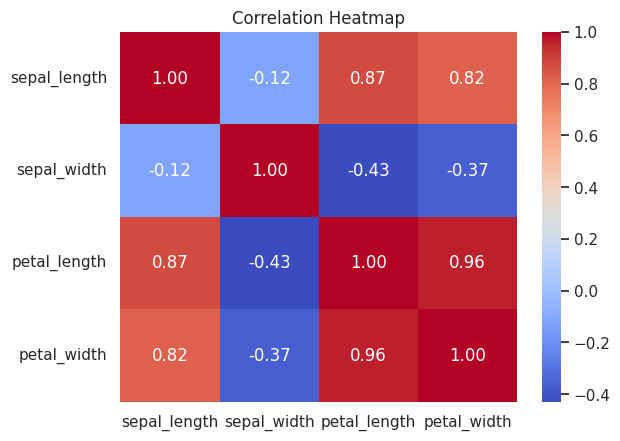

In [8]:
features = ["sepal_length", "sepal_width",
            "petal_length", "petal_width"]

corr = df[features].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

Count plot

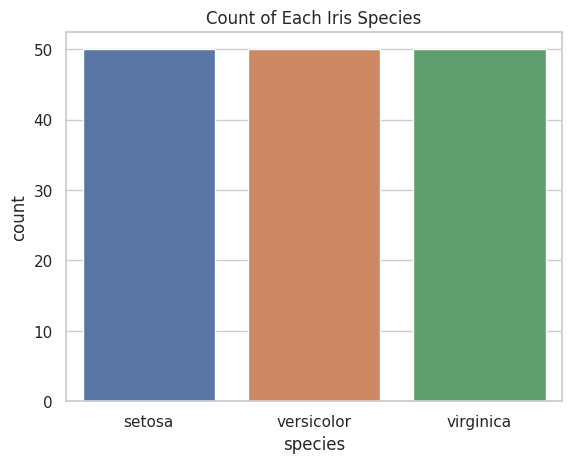

In [9]:
sns.countplot(data=df, x="species", hue="species",
              legend=False)
plt.title("Count of Each Iris Species")
plt.show()

KDE plot

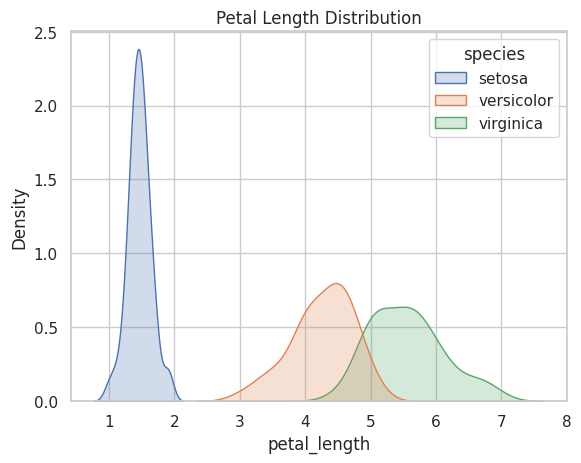

In [10]:
sns.kdeplot(
    data=df,
    x="petal_length",
    hue="species",
    fill=True,
    common_norm=False
)
plt.title("Petal Length Distribution")
plt.show()

Strip plot

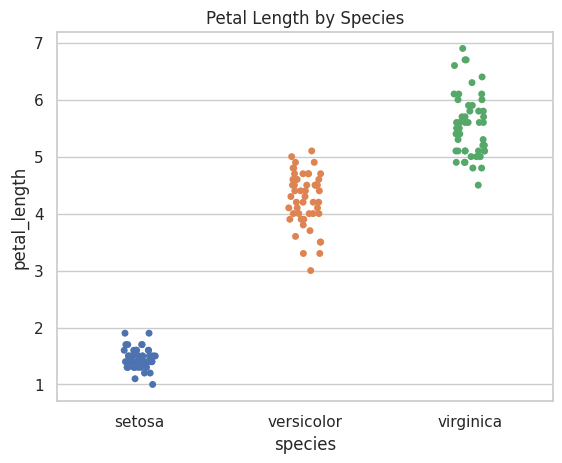

In [11]:
sns.stripplot(
    data=df,
    x="species",
    y="petal_length",
    hue="species",
    jitter=True,
    legend=False
)
plt.title("Petal Length by Species")
plt.show()